# Week 2 — Dataset & Baseline
## University Knowledge Assistant (RAG) · Group 4

**Data source:** *Student Resource Book (SRB) 2026*, MPSTME, SVKM's NMIMS (172-page PDF: Part I = university rules, Part II = MPSTME school rules).

This notebook completes every Week-2 task end to end and runs top to bottom in one go:

| Week-2 task | Where |
|---|---|
| Data collection | 1 — load the SRB PDF page by page |
| Cleaning | 2 — normalise text, remove page numbers / form blanks, drop out-of-scope pages |
| Preprocessing | 3 — tag sections, split into citable chunks, tokenise for keyword search |
| Annotation | 4 — 100 hand-written QA pairs (90 answerable + 10 out-of-scope), auto-validated |
| Train/test split | 5 — stratified dev (tuning) / test (final) split |
| Baseline model | 6 — BM25 keyword search + extractive answer with source and confidence |
| Initial evaluation | 7 — retrieval accuracy, citation accuracy, answer correctness, hallucination rate |


## 0. Setup

In [1]:
# Install anything missing (works on Colab and local Jupyter)
import importlib.util, subprocess, sys
for pip_name, module in [("pymupdf", "pymupdf"), ("rank_bm25", "rank_bm25"), ("nltk", "nltk"),
                         ("scikit-learn", "sklearn"), ("pandas", "pandas"), ("matplotlib", "matplotlib")]:
    if importlib.util.find_spec(module) is None:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", pip_name])

import os, re, unicodedata
from collections import Counter, defaultdict
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
try:
    import pymupdf
except ImportError:                                   # older PyMuPDF versions only expose `fitz`
    import fitz as pymupdf
from rank_bm25 import BM25Okapi
from nltk.stem import PorterStemmer
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS, TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.model_selection import train_test_split

PDF_PATH = "Student_Resource_Book__SRB__2026.pdf"   # keep the PDF next to this notebook
OUT_DIR = "week2_outputs"                           # CSVs for Week 3 are saved here
SEED = 42
os.makedirs(OUT_DIR, exist_ok=True)
pd.set_option("display.max_colwidth", 110)

if not os.path.exists(PDF_PATH):
    try:
        from google.colab import files               # Colab: upload the PDF when prompted
        PDF_PATH = next(iter(files.upload()))
    except ImportError:
        raise FileNotFoundError(f"Put the SRB PDF at '{PDF_PATH}' or change PDF_PATH.")
print("Using:", PDF_PATH)

Using: Student_Resource_Book__SRB__2026.pdf


## 1. Data collection

We read the SRB with **PyMuPDF**, one record per PDF page. The PDF page number is kept because it is what the assistant will cite as the source.
(We compared PyMuPDF with `pypdf` and `pdfplumber` on this file: PyMuPDF keeps two-column tables such as the *Code of Conduct → Line of Action* table in the correct reading order, the others interleave the columns.)

In [2]:
doc = pymupdf.open(PDF_PATH)
pages_raw = pd.DataFrame({
    "page": range(1, doc.page_count + 1),          # 1-based PDF page number (used for citations)
    "raw_text": [p.get_text() for p in doc],
})
pages_raw["n_words"] = pages_raw.raw_text.str.split().str.len()

print(f"Pages: {len(pages_raw)} | words: {pages_raw.n_words.sum():,}")
print("Pages with (almost) no text layer:", pages_raw[pages_raw.n_words < 20].page.tolist())
print("\nRaw sample (page 11):\n", pages_raw.raw_text[10][:400])

Pages: 172 | words: 60,404
Pages with (almost) no text layer: [2, 48, 66, 67, 169, 170]

Raw sample (page 11):
  
7 
3.2 
Attendance rules for all schools  
 
To ensure satisfactory attendance and engagement, 100% attendance in all subjects/courses is expected. However, exceptions 
may be made for valid medical reasons, personal reasons, and participation in extra-curricular and co-curricular activities, 
placement activities, institutional work, and other approved activities. A maximum relaxation of up to 


## 2. Cleaning

**Text cleaning** (applied to every page):
1. Unicode normalisation and curly quotes / dashes → plain ASCII (`’` → `'`, `–` → `-`).
2. Remove the printed page number at the top/bottom of each page.
3. Re-join lines that the PDF layout broke mid-sentence, and fix split hyphenation (`re- admission` → `re-admission`).
4. Remove fill-in-the-blank runs (`______`, `......`) and collapse extra whitespace.

In [3]:
CHAR_MAP = {"’": "'", "‘": "'", "“": '"', "”": '"', "–": "-", "—": "-", "\u00a0": " "}

def clean_page(text):
    text = unicodedata.normalize("NFKC", text)
    for a, b in CHAR_MAP.items():
        text = text.replace(a, b)
    lines = [l.strip() for l in text.split("\n") if l.strip()]
    if lines and lines[0].isdigit():            # printed page number (top)
        lines = lines[1:]
    if lines and lines[-1].isdigit():           # printed page number (bottom)
        lines = lines[:-1]
    text = " ".join(lines)                              # re-join broken lines
    text = re.sub(r"_{3,}|[.…]{4,}", " ", text)         # form blanks
    text = re.sub(r"(\w)-\s+(\w)", r"\1-\2", text)      # split hyphenation
    text = re.sub(r"\s+([,;:])", r"\1", text)           # space before punctuation
    return re.sub(r"\s+", " ", text).strip()

pages_raw["clean_text"] = pages_raw.raw_text.map(clean_page)
print("BEFORE:", repr(pages_raw.raw_text[9][:250]))
print("\nAFTER: ", pages_raw.clean_text[9][:250])

BEFORE: ' \n6 \n3.0 \nAttendance guidelines and Attendance rules : 100% Attendance in each course is expected. \n \n3.1 Attendance guidelines: \n3.1.1 \nA student is required to monitor his /her own attendance regularly.  All doubts regarding attendance should be \nc'

AFTER:  3.0 Attendance guidelines and Attendance rules: 100% Attendance in each course is expected. 3.1 Attendance guidelines: 3.1.1 A student is required to monitor his /her own attendance regularly. All doubts regarding attendance should be clarified with 


**Scope (which pages go into the knowledge base).** Our proposal targets rules, policies and guidelines, so we drop pages that contain no answerable rules:
cover/title pages, tables of contents, the blank application-form annexures (they would match keyword searches like *"refund"* without containing the rule), and the 86 pages of semester-wise curriculum tables (these need a table-aware parser; left for later).
The academic calendar pages are images with no text layer (OCR is future work).

In [4]:
EXCLUDE = {
    **{p: "Cover / part title page" for p in [1, 2, 67]},
    **{p: "Table of contents" for p in [4, 69]},
    **{p: "Annexures: blank application forms" for p in range(48, 67)},
    **{p: "Curriculum / course-list tables (later)" for p in range(83, 169)},
    **{p: "Academic calendar (image only, no text)" for p in [169, 170]},
}
pages_raw["status"] = pages_raw.page.map(EXCLUDE).fillna("KEPT: rules, policies, contacts")
pages = pages_raw[~pages_raw.page.isin(EXCLUDE)].copy()
assert (pages.clean_text.str.split().str.len() >= 20).all(), "a kept page is (almost) empty"

display(pages_raw.groupby("status").agg(pages=("page", "count"), words=("n_words", "sum")))
print(f"Knowledge base after cleaning: {len(pages)} pages, {pages.clean_text.str.split().str.len().sum():,} words")

,pages,words
status,,
"Academic calendar (image only, no text)",2,9
Annexures: blank application forms,19,3291
Cover / part title page,3,77
Curriculum / course-list tables (later),86,25451
"KEPT: rules, policies, contacts",60,31017
Table of contents,2,559


Knowledge base after cleaning: 60 pages, 30,916 words


## 3. Preprocessing

1. **Section tagging** — using the SRB's own table of contents, each page is cut at known section headings, so every piece of text knows which section it belongs to (e.g. *"3. Attendance Rules"*).
2. **Chunking** — overlapping word windows *inside* each page-section segment. A chunk never crosses a page or section boundary, so every answer can cite an exact page and section.
3. **Tokenisation for keyword search** — lowercase → alphanumeric tokens → remove stop-words → Porter stemming (`examinations` → `examin`).

In [5]:
# (PDF page, heading text as it appears on that page, section name)
SECTIONS = [
    (3, "Message from Vice-Chancellor", "Message from the Vice-Chancellor"),
    (5, "Student Guidelines", "1. About these Guidelines"),
    (5, "2 General Guidelines", "2. General Guidelines & Code of Conduct"),
    (10, "3.0 Attendance guidelines", "3. Attendance Rules"),
    (12, "4. Academic Guidelines", "4. Academic Guidelines"),
    (13, "5. Internal Continuous Assessment", "5. Internal Continuous Assessment (ICA)"),
    (14, "6. Interdisciplinary Offerings", "6. Interdisciplinary Offerings"),
    (14, "7. CHOICE BASED CREDIT SYSTEM", "7. Choice Based Credit System (CBCS)"),
    (15, "8. NMIMS-COURSERA INITIATIVE", "8. NMIMS-Coursera Initiative"),
    (16, "9. Examination Guidelines", "9. Examination Guidelines"),
    (23, "10. Policy on Award", "10. Awards, Prizes & Dean's List"),
    (24, "11. Guidelines for Scholarships", "11. Scholarships"),
    (25, "12. Guidelines for Admission Deferment", "12. Admission, Fees, Academic Break & Re-admission"),
    (28, "13. Guidelines for De-registration", "13. De-registration for Non-attendance"),
    (30, "14. Library Rules and Regulations", "14. Library Rules"),
    (31, "15. List of E-resources", "15. E-resources"),
    (32, "16. Guidelines for the Use of Computing Facilities", "16. Computing Facilities"),
    (34, "17. Students Portal", "17. Student Portal (LMS)"),
    (35, "18. Feedback Mechanism", "18. Feedback Mechanism"),
    (35, "19. Mentoring Programme", "19. Mentoring & Counselling"),
    (37, "20. Rules for Participating", "20. National/International Contests"),
    (37, "21 Guidelines for Annual Convocation", "21. Convocation"),
    (38, "22 Roles and Responsibilities", "22. Students' Council (NUSC)"),
    (39, "23 Fee-Related Procedures", "23. Fee-related Procedures & Refunds"),
    (40, "24 University level", "24. Anti-Ragging, ICC & Ombudsman"),
    (43, "25 Safety Guide", "25. Safety Guide (Floods, Fire, Earthquakes)"),
    (45, "26 The list of website categories", "26. Blocked Website Categories"),
    (46, "27 SVKM's NMIMS INFOLINE", "27. Infoline (Mumbai Campus)"),
    (47, "28 People you should know", "28. People You Should Know (University)"),
    (68, "Message from Dean", "MPSTME: Message from the Dean"),
    (70, "1. Academic/general inputs", "MPSTME 1. School Rules, Committees & CR"),
    (73, "2. Placement Guidelines", "MPSTME 2. Placements & Internships"),
    (76, "3. MPSTME International linkages", "MPSTME 3. International Linkages"),
    (77, "4. Examination Guidelines", "MPSTME 4. Passing Standards & Progression (ATKT)"),
    (79, "5. Promotion Rules: M. Tech. / MCA", "MPSTME 5. Promotion Rules (M Tech / MCA)"),
    (80, "6. Re-Examination Application", "MPSTME 6. Re-examination Fees"),
    (80, "7. Grading System", "MPSTME 7-8. Grading System & CGPA"),
    (81, "9. General Examination Rules", "MPSTME 9. General Examination Rules"),
    (82, "10. Admission Policy", "MPSTME 10-13. D.Voc Admission, Course Policy, Community Service"),
    (171, "17. LIST OF HOLIDAYS", "MPSTME 17. List of Holidays"),
    (172, "18. People you should know", "MPSTME 18. People You Should Know (School)"),
]

def split_into_sections(pages):
    """Cut each page at its known headings -> segments that never cross a page or section."""
    headings = defaultdict(list)
    for page, heading, name in SECTIONS:
        headings[page].append((heading, name))
    segments, current = [], "Front matter"
    for page, text in zip(pages.page, pages.clean_text):
        cuts = []
        for heading, name in headings[page]:
            pos = text.find(heading)
            assert pos >= 0, f"Heading '{heading}' not found on page {page}"
            cuts.append((pos, name))
        start = 0
        for pos, name in sorted(cuts):
            if text[start:pos].strip():
                segments.append((page, current, text[start:pos].strip()))
            current, start = name, pos
        segments.append((page, current, text[start:].strip()))
    return pd.DataFrame(segments, columns=["page", "section", "text"])

segments = split_into_sections(pages)
segments["part"] = np.where(segments.page < 67, "Part I (University)", "Part II (MPSTME)")
print(f"{len(segments)} segments in {segments.section.nunique()} sections")
segments.groupby(["part", "section"], sort=False).page.agg(first_page="min", last_page="max").head(10)

70 segments in 41 sections


first_page  \
part                section                                               
Part I (University) Message from the Vice-Chancellor                  3   
                    1. About these Guidelines                         5   
                    2. General Guidelines & Code of Conduct           5   
                    3. Attendance Rules                              10   
                    4. Academic Guidelines                           12   
                    5. Internal Continuous Assessment (ICA)          13   
                    6. Interdisciplinary Offerings                   14   
                    7. Choice Based Credit System (CBCS)             14   
                    8. NMIMS-Coursera Initiative                     15   
                    9. Examination Guidelines                        16   

                                                             last_page  
part                section                                             
Part I (University) Message from the Vice-Chancellor                 3  
                    1. About these Guidelines                        5  
                    2. General Guidelines & Code of Conduct          9  
                    3. Attendance Rules                             11  
                    4. Academic Guidelines                          13  
                    5. Internal Continuous Assessment (ICA)         14  
                    6. Interdisciplinary Offerings                  14  
                    7. Choice Based Credit System (CBCS)            14  
                    8. NMIMS-Coursera Initiative                    15  
                    9. Examination Guidelines                       23

In [6]:
def make_chunks(segments, size=100, overlap=25):
    """Overlapping word windows inside each segment; every chunk keeps its page + section."""
    rows = []
    for page, section, part, text in segments[["page", "section", "part", "text"]].itertuples(index=False):
        words, start = text.split(), 0
        while True:
            rows.append({"page": page, "section": section, "part": part,
                         "text": " ".join(words[start:start + size])})
            if start + size >= len(words):
                break
            start += size - overlap
    chunks = pd.DataFrame(rows)
    chunks.insert(0, "chunk_id", [f"C{i:04d}" for i in range(len(chunks))])
    chunks["n_words"] = chunks.text.str.split().str.len()
    return chunks

STEM = PorterStemmer().stem
def tokenize(text):
    """lowercase -> alphanumeric tokens -> drop stop-words -> Porter stem"""
    return [STEM(t) for t in re.findall(r"[a-z0-9]+", text.lower()) if t not in ENGLISH_STOP_WORDS]

chunks = make_chunks(segments, size=100, overlap=25)      # default size; tuned on dev in §7
print(f"{len(chunks)} chunks | words per chunk: mean {chunks.n_words.mean():.0f}, max {chunks.n_words.max()}")
print("Tokens:", tokenize("What is the minimum attendance required to appear for the end-semester examinations?"))
chunks.sample(3, random_state=SEED)[["chunk_id", "page", "section", "n_words", "text"]]

424 chunks | words per chunk: mean 94, max 100
Tokens: ['minimum', 'attend', 'requir', 'appear', 'end', 'semest', 'examin']


,chunk_id,page,section,n_words,text
145,C0145,21,9. Examination Guidelines,100,"or applications about revaluation to any other authorities within the School, Campus, or University. 9.6.6..."
280,C0280,39,23. Fee-related Procedures & Refunds,100,"have failed and wish to re-appear for an examination will be required to pay re-examination fees, which sh..."
175,C0175,25,"12. Admission, Fees, Academic Break & Re-admission",100,apply online for cancellation of his / her seat along with the original fee receipt and cancelled cheque (...


## 4. Annotation

There is no public QA dataset for our SRB, so we wrote one. Each item was written by reading the SRB and records:

| Field | Meaning |
|---|---|
| `topic` | one of 13 areas (attendance, exams, fees, library …) — used for the stratified split |
| `question` | how a student would actually ask it (paraphrased, **not** copied from the SRB) |
| `answer` | reference answer in simple language (used for generated answers in Week 3) |
| `answer_key` | the key fact that a correct answer must contain (`\|` separates acceptable alternatives) |
| `evidence` | a short **verbatim** span (≤ 20 words) from the SRB that proves the answer (`\|` separates spans when the SRB states the same rule in two places) |
| `page` | PDF page of the (first) evidence span |

We also added **10 out-of-scope questions** whose answer is *not* in the SRB (e.g. hostel curfew, Wi-Fi password; checked by searching the PDF). A trustworthy assistant should refuse these instead of answering, this is how we measure hallucination.

Gold chunks are **not** hard-coded: for any chunking setting, the gold chunks are simply the chunks that contain an evidence span, and the gold pages are their pages. This lets us change chunk size without re-annotating.

In [7]:
# (topic, question, reference answer, answer key, evidence span, PDF page)
QA = [
# ---------------- Attendance ----------------
("attendance", "What is the minimum attendance required to appear for the end-semester exam?",
 "You need at least 80% attendance in each individual course.", "80%",
 "Students who have maintained 80% or higher attendance in individual courses", 11),
("attendance", "I was marked absent even though I was in class. What should I do?",
 "Inform the concerned faculty immediately with a written application stating you were present, and keep a copy.", "written application",
 "he/she should immediately inform the concerned faculty by submitting a written application", 10),
("attendance", "How many days do I have to report a mistake in the monthly attendance report?",
 "Within 3 days of the attendance record being published; no claims are accepted after that.", "3 days",
 "within 3 days of the publication of the attendance record", 10),
("attendance", "When will my parents be informed about my attendance?",
 "If your monthly attendance is below 80%, parents are informed by email/WhatsApp.", "less than 80%",
 "if the student has less than 80% attendance monthly through email/WhatsApp", 10),
("attendance", "By when should I submit a medical certificate after coming back from medical leave?",
 "Within 3 days of resuming classes, along with copies of all medical reports.", "within 3 days of resuming",
 "within 3 days of resuming classes after medical leave", 10),
("attendance", "What happens if my attendance in a subject goes below 80%?",
 "You will have to take re-admission, either in the same semester or for the full year in the next academic year.", "re-admission",
 "Students will be required to take re-admission. Students can opt", 11),
("attendance", "Am I marked present in regular classes on the day I write a re-exam?",
 "Yes. You are marked present for all applicable subjects on the day of your re-examination.", "marked present",
 "such students shall be marked present for all applicable subjects on that day", 10),
("attendance", "How much absence can be relaxed for medical reasons or extra-curricular activities?",
 "Up to 20% absence can be relaxed, as long as attendance stays at 80% or above in each course.", "20%",
 "A maximum relaxation of up to 20% absence may be granted", 11),
# ---------------- Academics & ICA ----------------
("academics_ica", "What is the minimum duration of a term end exam?",
 "At least 2 hours.", "2 hrs",
 "Minimum duration of Term End Examinations: 2 hrs", 13),
("academics_ica", "What do I need to score to pass a course that has only ICA and no final exam?",
 "At least 40% of the total ICA marks.", "40%",
 "The passing criteria for such ONLY ICA courses will be at 40% minimum of total of ICA marks", 13),
("academics_ica", "Is there a re-exam if I fail an only-ICA course?",
 "No. There is no re-exam for only-ICA courses; you must take re-admission.", "no re-examination",
 "there will be no re-examination for Only ICA Courses", 13),
("academics_ica", "Can grace marks be added to my internal (ICA) marks?",
 "No. Grace marks are never awarded on the ICA component.", "never",
 "Grace Marks will never be awarded on the ICA (Internal Continuous Assessment) component|Grace marks will never to be awarded on ICA", 13),
("academics_ica", "How long do I have to raise an issue about my ICA marks on the portal?",
 "Within two days of the marks being published.", "two days",
 "should be informed and resolved within two days of publication on the portal", 13),
("academics_ica", "If I am caught copying in an assignment and allowed to resubmit, how many marks can I get?",
 "50% of the total marks or your actual marks, whichever is lower (for group work this applies to everyone).", "50%",
 "the student will be awarded 50% of the total marks or actual marks, whichever is lower", 14),
("academics_ica", "How many interdisciplinary courses can I take?",
 "A maximum of 2: one in the fall session and one in the winter session.", "maximum of 2",
 "allowed to choose a maximum of 2 courses", 14),
("academics_ica", "Can first-year undergraduate students take CBCS courses?",
 "No. First-year UG students are not eligible for CBCS courses.", "not eligible",
 "are not eligible to opt CBCS courses", 14),
("academics_ica", "How long is the Coursera license valid?",
 "For one academic year only.", "one academic year",
 "Coursera license which will be valid for one academic year only", 15),
("academics_ica", "Where do I email an academic grievance?",
 "Write to grievance.academic@nmims.edu.", "grievance.academic@nmims.edu",
 "the student may write to grievance.academic@nmims.edu", 15),
# ---------------- Exam conduct & unfair means ----------------
("exam_conduct", "How early should I reach the exam hall?",
 "At least 30 minutes before the exam starts.", "30 minutes before",
 "at least 30 minutes before the scheduled time of the commencement of the examination", 16),
("exam_conduct", "Can I still write the exam if I come more than 30 minutes late?",
 "No. Students arriving after 30 minutes are not allowed under any circumstances.", "not be allowed",
 "will not be allowed to write examination under any circumstances", 16),
("exam_conduct", "Is a smart watch allowed in the exam hall?",
 "No. Smart watches and similar devices are forbidden and will be confiscated.", "smart watch",
 "notes, scribbling papers, mobile phones, smart watch", 16),
("exam_conduct", "Can I write my name or roll number on the answer book?",
 "No. Answer books are QR coded; revealing your identity is treated as unfair means.", "qr coded|not write",
 "The answer books of the term-end examinations will be QR coded", 17),
("exam_conduct", "What is the punishment for impersonation in an exam?",
 "Permanent expulsion from the University.", "permanent expulsion",
 "Impersonation for a student or impersonation by a student in University or other examinations", 19),
("exam_conduct", "What happens if a student is caught using unfair means more than twice?",
 "Permanent expulsion from the University.", "permanent expulsion",
 "Student involved in uses of Unfair Means more than two occasions", 20),
("exam_conduct", "What is the punishment for trying to bribe an examiner?",
 "Exclusion from four additional examinations; the money goes to the Students Welfare Fund.", "four additional examinations",
 "Insertion of currency notes/ bribing or attempt to bribe", 19),
# ---------------- Exam support (scribe / LD) ----------------
("exam_support", "How much extra time does a student with a scribe get?",
 "20 minutes per hour (e.g. 40 minutes for a 2-hour exam).", "20 minutes per hour",
 "compensatory time of 20 minutes per hour will be allowed", 17),
("exam_support", "How early do I need to arrange a scribe for my exam?",
 "At least one week before the exam, and inform the examination office.", "one week",
 "at least one week before the examination", 17),
("exam_support", "Which hospitals can issue the learning disability certificate for the Mumbai campus?",
 "Only Sion Hospital or Nair Hospital.", "sion hospital|nair hospital",
 "medical certificate from Sion Hospital / Nair Hospital only would be accepted", 18),
("exam_support", "Can students with dyslexia get grace marks?",
 "Yes, up to 3% of the aggregate marks of the subjects appeared in.", "3 per cent",
 "eligible for grace marks up to 3 per cent of the aggregate", 18),
# ---------------- Results, revaluation & grace ----------------
("results_revaluation", "Within how many days of the result can I ask for a photocopy of my answer sheet?",
 "Within 2 days from the date of result declaration (including holidays).", "2 days",
 "Application for Photocopy/ Softcopy of the Answer Script Within 2 days", 21),
("results_revaluation", "What is the deadline to apply for retotalling of marks?",
 "Within 3 days from the date of result declaration (including holidays).", "3 days",
 "Application for Verification (retotalling of marks)", 21),
("results_revaluation", "Can I apply for revaluation without taking a photocopy of my answer script?",
 "No. You must first apply for the photocopy to be eligible for revaluation.", "not be eligible",
 "Students will not be eligible to apply for revaluation if they do not apply for a Photocopy", 21),
("results_revaluation", "What happens if revaluation changes my marks by more than 20%?",
 "A second revaluation is done and the better of the two revaluations becomes final.", "second revaluation",
 "Second revaluation of the said answer book shall be done", 22),
("results_revaluation", "How long does the whole grievance redressal process take?",
 "It is completed within 15 working days of receiving the application.", "15 working days",
 "completed within a period of 15 working days", 23),
("results_revaluation", "How many grace marks can a student who fails get?",
 "Up to 2% of aggregate marks, maximum 6 marks overall, and not more than 3% per subject.", "2 per cent|6 marks",
 "grace marks up to 2 per cent of the marks on the aggregate marks", 23),
("results_revaluation", "Can I apply for revaluation of my viva or lab exam?",
 "No. Grievance redressal applies only to term-end exams, not practicals, labs, viva or projects.", "will not apply",
 "The above mechanism will not apply to practicals / Labs / oral examinations", 21),
# ---------------- Awards & scholarships ----------------
("awards_scholarships", "What percentage of students make it to the Dean's list?",
 "The top 10% of the batch by CGPA.", "10%",
 "10% of the batch (top 10% students) on the basis of highest CGPA", 23),
("awards_scholarships", "How many prizes are given if my batch has 30 students?",
 "Two prizes (for batches of 21 to 59 students).", "two prizes",
 "two prizes will be awarded where the number of students in the batch/stream is between 21 and 59", 23),
("awards_scholarships", "Can a student with an ATKT be on the rank holder list?",
 "No. Students with F grades/ATKT or misconduct are ineligible.", "ineligible",
 "Students obtaining F grades/ATKT/ involved in unfair means or any misconduct will be ineligible", 23),
("awards_scholarships", "Who gets disqualified from the awards and scholarships process?",
 "Students with an F grade, a misconduct record or low attendance are automatically disqualified.", "automatically disqualified",
 "will be automatically disqualified from the awards process", 24),
("awards_scholarships", "Where can I apply for government scholarships?",
 "Through the National Scholarship Portal (NSP), scholarships.gov.in.", "national scholarship portal|nsp",
 "can avail national scholarship through the National Scholarship Portal (NSP)", 24),
("awards_scholarships", "Is there any scholarship for girls in technical courses?",
 "Yes, the AICTE Pragati Scholarship Scheme for Girl Students, via NSP.", "pragati",
 "Pragati Scholarship Scheme for Girl Students", 24),
# ---------------- Admission, academic break & re-admission ----------------
("admission_readmission", "For what reasons can I defer my admission?",
 "Serious medical illness or serious family-related reasons.", "medical illness|family-related",
 "Serious medical illness", 25),
("admission_readmission", "Can a second-year student get admission deferment?",
 "No. Admission deferment can be approved only for the first year.", "only for first year|first-year students",
 "Admission deferment can be approved only for first year|Deferred admission may only be granted to first-year students", 25),
("admission_readmission", "On what grounds can I take an academic break?",
 "Serious medical reasons, serious family issues, or financial constraints.", "medical|financial constraints",
 "Serious personal medical reasons involving hospitalisation", 26),
("admission_readmission", "How many times can I take an academic break during my program?",
 "At most twice, as long as the total break does not exceed one year.", "twice",
 "granted to any student at best twice during the programme", 26),
("admission_readmission", "How much is the re-admission fee?",
 "25% of the total fee prevailing at the time of re-admission.", "25%",
 "he / she has to pay 25% of the total fee prevalent", 27),
("admission_readmission", "Can the 25% re-admission fee ever be waived?",
 "Yes, if the break is on health grounds and attendance was below 20%.", "waived",
 "the 25% fee for re-admission could be waived off", 27),
("admission_readmission", "How many times can I take re-admission in the same year of my program?",
 "Only once.", "only once",
 "Students can take re-admission in the said year of the program only once", 27),
("admission_readmission", "What happens if I don't pay my fees even after the late-fee period?",
 "Your studentship in the program is cancelled.", "cancellation of the studentship",
 "Non-payment of fees within the stipulated time, including the late fee period", 26),
# ---------------- Conduct & discipline ----------------
("conduct_discipline", "Are mobile phones allowed on campus?",
 "No. Mobile phones, smart glasses and similar devices are not permitted on campus.", "not permitted",
 "The use of mobile phones, Meta Smart Glasses, or any similar electronic devices on campus is not permitted", 5),
("conduct_discipline", "Can I eat in the classroom?",
 "No. Only drinking water is allowed inside the classroom.", "drinking water",
 "Only drinking water is allowed inside the classroom", 5),
("conduct_discipline", "What should I do if I forget my ID card?",
 "Approach security and complete the process to get access; ID grievances go to biometricregistration@svkm.ac.in.", "approach security",
 "In case a student forgets to carry an ID card, they should approach security", 6),
("conduct_discipline", "What is the dress code for university events and guest lectures?",
 "Formals with the institute blazer, tie/cravat and lapel pin.", "blazer",
 "dress in formals, Institute blazer, Tie/ Cravat, and Lapel Pin", 9),
("conduct_discipline", "Who hears appeals in disciplinary cases?",
 "The Chancellor of the University is the appellate authority.", "chancellor",
 "the Chancellor of the University will be the appellate authority", 9),
("conduct_discipline", "Who sits on the school's disciplinary committee?",
 "The Chairperson/Head of Department, one faculty member and one staff member.", "one staff member",
 "The committee comprises the Chairperson / Head of the Department, one faculty member and one staff member", 9),
("conduct_discipline", "Do I need permission to travel out of the city during the term?",
 "Yes, prior permission from the HOD/Director/Dean is required.", "prior permission",
 "they are required to obtain prior permission from the HOD/Director/Dean", 9),
("conduct_discipline", "Where do I fill the anti-ragging undertaking?",
 "Online at www.antiragging.in or www.amanmovement.org.", "antiragging.in|amanmovement.org",
 "www.amanmovement.org (OR) www.antiragging.in", 40),
("conduct_discipline", "Who is the chairperson of the MPSTME anti-ragging committee?",
 "Dr. Koteswararao Anne.", "koteswararao anne",
 "1.5.1 Anti-Ragging Committee 1. Dr. Koteswararao Anne Chairperson", 71),
("conduct_discipline", "Who heads the University's Internal Complaints Committee for sexual harassment?",
 "Dr. Meena Galliara (Chairperson).", "meena galliara",
 "1. Dr. Meena Galliara, Director, (Jasani Centre", 41),
# ---------------- Library ----------------
("library", "How many library books can I borrow and for how long?",
 "Two books for ten days, with one renewal if the book is not in demand.", "two books for ten days",
 "Borrowing entitlement: Two books for ten days", 30),
("library", "What is the fine for returning a library book late?",
 "Rs. 3 per day per book.", "rs.3.00|rs. 3",
 "A fine of Rs.3.00 per day per book is levied on overdue books", 30),
("library", "What happens if I use my phone in the library?",
 "It can lead to a fine, exclusion from the library and/or a three-week suspension.", "three week suspension",
 "Violating the rules will lead to a student's penalty and /or three week suspension", 30),
("library", "Will I get my degree if I still have library books or fines pending?",
 "No. The award of the qualification is deferred until all books are returned and fines paid.", "deferred",
 "The award of SVKM's NMIMS qualification will be deferred until all books", 30),
# ---------------- IT & student portal ----------------
("it_portal", "How much OneDrive storage do students get?",
 "50 GB.", "50 gb",
 "Students will get 50 GB of space in OneDrive", 32),
("it_portal", "How early should I ask IT for extra internet bandwidth for an event?",
 "At least 72 hours in advance.", "72 hours",
 "a request should reach the IT helpdesk minimum 72 hours in advance", 33),
("it_portal", "What is my default username for the student portal?",
 "Your SAP number; the password is mailed by the admin/course coordinator.", "sap number",
 "Default User ID is the student's SAP number", 34),
("it_portal", "Can I plug my pen drive into the classroom smartboard?",
 "No. Personal pen drives and laptops cannot be connected to classroom systems/smartboards.", "not allowed",
 "Students are not allowed to connect personal pen drives/ Laptops to the systems/smartboard", 32),
("it_portal", "How do I get access to a website that is blocked on the campus network?",
 "Email ITHelpdesk@nmims.edu; access is granted if the content is found appropriate.", "ithelpdesk@nmims.edu",
 "request to send an email to ITHelpdesk@nmims.edu", 32),
("it_portal", "Can I book a hostel room through the student portal?",
 "Yes, hostel booking is available on the portal once online admission and full payment are done.", "book a hostel",
 "Students can book a hostel through the portal", 34),
# ---------------- Student services, fees & refunds ----------------
("student_services", "Do I get travel reimbursement for a Grade B contest?",
 "Only if you win 1st or 2nd place; then travel is reimbursed 100% (non-AC sleeper/3-tier).", "1st or 2nd",
 "provided that they have won the contest (1st or 2nd place only)", 37),
("student_services", "How soon after winning a contest must I submit the details?",
 "Within 7 days of winning, or it won't be considered for appraisal.", "7 days",
 "within 7 days of winning the contest", 37),
("student_services", "How long does it take to get my hostel deposit refunded?",
 "Allow 3 weeks after submitting the signed receipt and refund application to Accounts.", "3 weeks",
 "procure the signature of the Hostel in-charge on the receipt", 39),
("student_services", "How quickly must expenses for a student activity be settled?",
 "Within 72 hours, along with the activity report.", "72 hours",
 "they must be settled within 72 hours along with the report of activities", 39),
("student_services", "How can MPSTME students reach the university psychologist?",
 "Call 022-42332225 / 022-42334090 or email Nazneen.raimalwala@nmims.edu or ketaki.gokhale@nmims.edu.", "nazneen.raimalwala@nmims.edu|ketaki.gokhale@nmims.edu",
 "email Nazneen.raimalwala@nmims.edu", 36),
("student_services", "If I'm found ineligible for my degree at convocation, by when can I appeal?",
 "At least 48 hours before the convocation ceremony.", "48 hours",
 "at least 48 hours before the Annual Convocation", 37),
("student_services", "Is Maharashtra Day a university holiday?",
 "Yes, 1 May (Maharashtra Day) is a holiday and one of the national holidays when no classes are held.", "maharashtra day",
 "01-May-25 Thursday Maharashtra Day", 171),
# ---------------- MPSTME: passing, progression, re-exams, grading ----------------
("mpstme_exams", "What do I need to score to pass a course?",
 "At least 40% in the semester-end exam and at least 40% aggregate (ICA + exam).", "40%",
 "Secure a minimum of 40% marks in the Term / Semester end examination of that course", 77),
("mpstme_exams", "How many F grades can I have and still move to the next year in B Tech?",
 "Up to two F grades after re-exams; you then re-appear for those courses next year.", "up to two",
 "A student who has obtained up to two 'F' grades in B Tech / MBA Tech/ Diploma program", 78),
("mpstme_exams", "What happens if I get more than two F grades in a year?",
 "You are not promoted; you can take re-admission for the whole year or take a 'year back' and re-appear only for the failed exams.", "not be promoted",
 "would not be promoted to the next year of the programme", 78),
("mpstme_exams", "What is the re-exam fee per subject?",
 "Rs. 1,000 per subject.", "1,000",
 "The fee for submission of a re-examination application shall be Rs. 1,000/-", 80),
("mpstme_exams", "What is the late fee if I miss the re-exam application deadline?",
 "Rs. 5,000 (in addition to Rs. 1,000 per subject), payable in a 24-hour late window.", "5,000|5000",
 "allowed to submit their application with late fees of Rs. 5000/-", 80),
("mpstme_exams", "For how many days is the re-exam application portal open?",
 "Three days; it closes at 4:00 PM on the third day.", "three (3) days|4:00 pm",
 "will remain open for three (3) days", 80),
("mpstme_exams", "How are the marks split between internals and the semester-end exam?",
 "ICA is 50 marks and the semester-end exam is 100 marks scaled down to 50, for a total of 100.", "scaled down to 50",
 "100 (scaled down to 50 marks)", 77),
("mpstme_exams", "What happens if I am absent for a semester-end exam?",
 "You are marked 'AB' for that course and can appear for the re-examination.", "marked as 'ab'",
 "shall be marked as 'AB' in the result", 81),
# ---------------- MPSTME: placements, internships & school ----------------
("mpstme_school", "How long is the internship for B Tech students?",
 "An entire semester (the last semester of the year).", "entire semester",
 "Internship duration for B Tech, and MCA - entire semester", 74),
("mpstme_school", "What if I don't want to sit for campus placements?",
 "Formally notify the Placement Office using the 'Opted Out Form' with your reason.", "opted out form",
 "formally notify the Placement Office vide the 'Opted Out Form'", 74),
("mpstme_school", "What CGPA does a D.Voc student need to join B Tech first year?",
 "A minimum of 6.5 based on first- and second-year exams.", "6.5",
 "Candidates must have secured a minimum CGPS of 6.5", 82),
("mpstme_school", "When is the community service course done?",
 "Any three consecutive weeks in the summer vacation between Semester II and Semester III.", "three weeks",
 "any consecutive three weeks during the summer vacation between Semester-II and Semester-III", 82),
("mpstme_school", "How is the class representative (CR) chosen?",
 "The top three students by Class XII aggregate are nominated; the HoD selects the final CR after interaction.", "class xii",
 "The first three students, based on their Class XII aggregate marks", 72),
# ---------------- Out of scope (answer is NOT in the SRB) ----------------
("out_of_scope", "What is the hostel curfew time for students?", "", "", "", None),
("out_of_scope", "What is the annual tuition fee for B Tech Data Science?", "", "", "", None),
("out_of_scope", "What is the campus Wi-Fi password?", "", "", "", None),
("out_of_scope", "What time does the college canteen close?", "", "", "", None),
("out_of_scope", "Is there a gym on campus and what are its timings?", "", "", "", None),
("out_of_scope", "What is the average placement package for B Tech students?", "", "", "", None),
("out_of_scope", "When is the MPSTME college fest held?", "", "", "", None),
("out_of_scope", "What is the NPAT cutoff score for B Tech admission?", "", "", "", None),
("out_of_scope", "Is there a college shuttle bus from the railway station?", "", "", "", None),
("out_of_scope", "How much is the parking fee for two-wheelers on campus?", "", "", "", None),
]

In [8]:
qa = pd.DataFrame(QA, columns=["topic", "question", "answer", "answer_key", "evidence", "page"])
qa.insert(0, "qid", [f"Q{i:03d}" for i in range(1, len(qa) + 1)])
qa["answerable"] = qa.evidence != ""
qa["page"] = qa.page.astype("Int64")

def norm(s):
    """Same cleaning as the corpus + lowercase, so evidence/keys can be matched as substrings."""
    return clean_page(s).lower()

# ---- automatic annotation checks ----
page_text = dict(zip(pages.page, pages.clean_text.map(norm)))
problems = []
for r in qa.itertuples():
    if not r.answerable:
        if r.answer_key or pd.notna(r.page):
            problems.append((r.qid, "out-of-scope item should have no key/page"))
        continue
    spans = [norm(e) for e in r.evidence.split("|")]
    evidence_pages = [p for p, t in page_text.items() if any(e in t for e in spans)]
    if spans[0] not in page_text.get(r.page, ""):
        problems.append((r.qid, "evidence not found on the annotated page"))
    if any(not any(e in t for t in page_text.values()) for e in spans):
        problems.append((r.qid, "an evidence span is not in the corpus"))
    if not any(k.strip().lower() in page_text[p] for p in evidence_pages for k in r.answer_key.split("|")):
        problems.append((r.qid, "answer key not found next to the evidence"))
    if any(len(e.split()) > 20 for e in spans):
        problems.append((r.qid, "evidence longer than 20 words"))
if qa.question.duplicated().any():
    problems.append(("-", "duplicate questions"))
assert not problems, problems
print(f"All {len(qa)} annotations passed: {qa.answerable.sum()} answerable + {(~qa.answerable).sum()} out-of-scope")

overlap = [len(set(tokenize(q)) & set(tokenize(e.split("|")[0]))) / len(set(tokenize(q)))
           for q, e in zip(qa.question, qa.evidence) if e]
print(f"On average only {np.mean(overlap):.0%} of a question's keywords appear in its evidence (questions are paraphrased)")
qa.to_csv(f"{OUT_DIR}/qa_annotations.csv", index=False)
qa[["qid", "topic", "question", "answer_key", "page"]].head(8)

All 100 annotations passed: 90 answerable + 10 out-of-scope


On average only 35% of a question's keywords appear in its evidence (questions are paraphrased)


,qid,topic,question,answer_key,page
0,Q001,attendance,What is the minimum attendance required to appear for the end-semester exam?,80%,11
1,Q002,attendance,I was marked absent even though I was in class. What should I do?,written application,10
2,Q003,attendance,How many days do I have to report a mistake in the monthly attendance report?,3 days,10
3,Q004,attendance,When will my parents be informed about my attendance?,less than 80%,10
4,Q005,attendance,By when should I submit a medical certificate after coming back from medical leave?,within 3 days of resuming,10
5,Q006,attendance,What happens if my attendance in a subject goes below 80%?,re-admission,11
6,Q007,attendance,Am I marked present in regular classes on the day I write a re-exam?,marked present,10
7,Q008,attendance,How much absence can be relaxed for medical reasons or extra-curricular activities?,20%,11


## 5. Train / test split

A RAG system has no trainable weights at this stage, so instead of *train* we keep a **development (dev) set** for tuning our few settings (chunk size, abstain threshold). The **test set** is used only once, for the final numbers.
Split: 40% dev / 60% test, **stratified by topic** so every topic (and the out-of-scope questions) appears in both.

dev : 40 questions (36 answerable, 4 out-of-scope)
test: 60 questions (54 answerable, 6 out-of-scope)


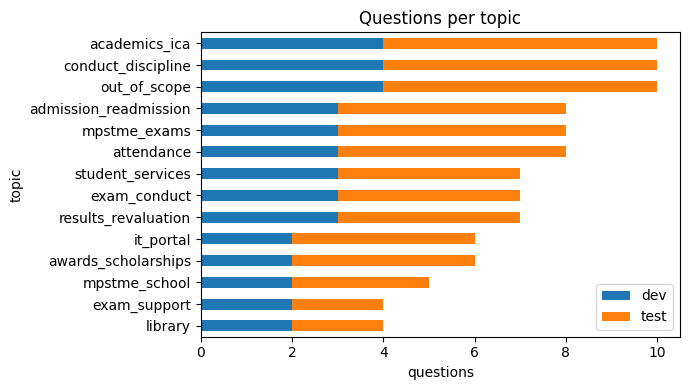

In [9]:
dev, test = train_test_split(qa, test_size=0.60, stratify=qa.topic, random_state=SEED)
dev = dev.sort_values("qid").reset_index(drop=True)
test = test.sort_values("qid").reset_index(drop=True)
assert set(dev.qid).isdisjoint(test.qid) and len(dev) + len(test) == len(qa)
dev.to_csv(f"{OUT_DIR}/qa_dev.csv", index=False)
test.to_csv(f"{OUT_DIR}/qa_test.csv", index=False)

print(f"dev : {len(dev)} questions ({dev.answerable.sum()} answerable, {(~dev.answerable).sum()} out-of-scope)")
print(f"test: {len(test)} questions ({test.answerable.sum()} answerable, {(~test.answerable).sum()} out-of-scope)")
counts = pd.concat([dev.topic.value_counts().rename("dev"), test.topic.value_counts().rename("test")], axis=1)
counts.loc[counts.sum(axis=1).sort_values().index].plot.barh(stacked=True, figsize=(7, 4), title="Questions per topic")
plt.xlabel("questions"); plt.tight_layout(); plt.show()

## 6. Baseline model

As planned in Week 1, the baseline uses **keyword search only — no AI writing**:

1. **Retrieve** — rank all chunks with **BM25** (the standard keyword-ranking function). TF-IDF + cosine similarity is included as a second keyword retriever for comparison.
2. **Answer** — from the top chunk, return the sentence that shares the most keywords with the question, copied word-for-word.
3. **Source** — part, section and PDF page of that chunk.
4. **Confidence** — how much of the question is covered by the cited chunk: the share of the question's keywords found in it, with each keyword weighted by its rarity (IDF). A word that never occurs in the SRB (e.g. *curfew*) gets the highest weight, so questions about things the SRB does not cover get low confidence.
5. **Abstain** — if confidence is below a threshold (tuned on dev), reply *"not found"* instead of guessing.

The output has the same four fields as our proposal: `answer`, `source`, `confidence`, `supporting_text`.

In [10]:
class BM25Retriever:
    def __init__(self, chunks):
        self.ids = chunks.chunk_id.tolist()
        self.bm25 = BM25Okapi([tokenize(t) for t in chunks.text])

    def search(self, query, k=5):
        scores = self.bm25.get_scores(tokenize(query))
        top = np.argsort(-scores, kind="stable")[:k]
        return [(self.ids[i], float(scores[i])) for i in top]


class TfidfRetriever:
    def __init__(self, chunks):
        self.ids = chunks.chunk_id.tolist()
        self.vectorizer = TfidfVectorizer(tokenizer=tokenize, lowercase=False, token_pattern=None)
        self.matrix = self.vectorizer.fit_transform(chunks.text)

    def search(self, query, k=5):
        scores = cosine_similarity(self.vectorizer.transform([query]), self.matrix).ravel()
        top = np.argsort(-scores, kind="stable")[:k]
        return [(self.ids[i], float(scores[i])) for i in top]

In [11]:
# sentence boundaries: end punctuation, bullets, or clause numbers like "3.1.4"
SENT_SPLIT = re.compile(r"(?<=[.;?!])\s+(?=[A-Z(•'\"])|\s+(?=•)|\s+(?=\d{1,2}(?:\.\d{1,2}){1,3}\s)")

def split_sentences(text):
    parts = [s.strip(" •") for s in SENT_SPLIT.split(text)]
    return [s for s in parts if len(s.split()) >= 3] or [text]

def extract_answer(question, passage):
    """Return the passage sentence that shares the most keywords with the question (verbatim)."""
    q_terms = set(tokenize(question))
    sents = split_sentences(passage)
    best = int(np.argmax([len(q_terms & set(tokenize(s))) for s in sents]))
    if len(sents[best].split()) < 8 and best + 1 < len(sents):      # too short -> include next sentence
        start = passage.find(sents[best])
        return passage[start: passage.find(sents[best + 1], start) + len(sents[best + 1])]
    return sents[best]


class KeywordQA:
    """Week-2 baseline: keyword retrieval + extractive answer + source + confidence."""
    NOT_FOUND = "I could not find this in the Student Resource Book."

    def __init__(self, chunks, retriever=BM25Retriever, threshold=0.0, k=5):
        self.chunks = chunks.set_index("chunk_id")
        self.retriever = retriever(chunks)
        self.threshold, self.k = threshold, k
        # IDF weights for the confidence score (rare words matter more)
        doc_freq = Counter(t for text in chunks.text for t in set(tokenize(text)))
        n = len(chunks)
        self.idf = {t: np.log((n + 1) / (df + 1)) + 1 for t, df in doc_freq.items()}
        self.unseen_idf = np.log(n + 1) + 1                   # word that never appears in the SRB

    def confidence(self, question, passage):
        q_terms = set(tokenize(question))
        if not q_terms:
            return 0.0
        weight = {t: self.idf.get(t, self.unseen_idf) for t in q_terms}
        found = q_terms & set(tokenize(passage))
        return sum(weight[t] for t in found) / sum(weight.values())

    def ask(self, question):
        hits = self.retriever.search(question, self.k)
        top = self.chunks.loc[hits[0][0]]
        confidence = self.confidence(question, top.text)
        extracted = extract_answer(question, top.text)
        abstained = confidence < self.threshold
        return {
            "answer": self.NOT_FOUND if abstained else extracted,
            "source": f"SRB 2026 | {top.part} | {top.section} | PDF page {top.page}",
            "confidence": round(confidence, 2),
            "supporting_text": top.text,
            # extra fields used only for evaluation
            "extracted": extracted, "abstained": abstained,
            "cited_page": int(top.page), "ranked_ids": [c for c, _ in hits],
        }

def show(out, question):
    print("Q:", question)
    for field in ["answer", "source", "confidence"]:
        print(f"  {field:<15}: {out[field]}")
    print(f"  supporting_text: {out['supporting_text'][:220]}...\n")

demo_system = KeywordQA(chunks)                      # default settings, no refusals yet
for q in ["Is a smart watch allowed in the exam hall?",
          "What is the minimum attendance required to appear for the end-semester exam?"]:   # example from our proposal
    show(demo_system.ask(q), q)

Q: Is a smart watch allowed in the exam hall?
  answer         : 9.1.13 Students are forbidden to (i) bring any books, notes, scribbling papers, mobile phones, smart watch, health band with data storage communication facility, in ear Bluetooth speaker, micro scanner, micro phone, micro camera, micro speaker, memory based modules, Wi-Fi enabled modules, earbuds, storable/programmable or financial calculators, laptop, Bluetooth devices,
  source         : SRB 2026 | Part I (University) | 9. Examination Guidelines | PDF page 16
  confidence     : 0.66
  supporting_text: with as per the rules. 9.1.12 QUERY REGARDING QUESTIONS IN THE EXAMINATION QUESTION PAPER: If a student has any query as regards to the contents of the question paper, he / she should bring the same to the notice of the ...

Q: What is the minimum attendance required to appear for the end-semester exam?
  answer         : 4.1 PASSING STANDARDS FOR EACH COURSE (SUBJECT): Semester-end-exam Passing Criteria for each Course: T

The first answer is correct and cites the right rule. The second one, the example from our own proposal is **wrong**: the correct rule (80% attendance, page 11) loses to the *passing criteria* rule on page 77 because that passage repeats the question's words *minimum*, *semester*, *examination* and *appear* more often. This is exactly the keyword-versus-meaning gap that the embedding-based version in Week 3 has to close. Section 7 measures how often it happens.

## 7. Initial evaluation

**Metrics** (the four from our proposal):

| Proposal metric | How we measure it |
|---|---|
| Retrieval accuracy | **Hit@k** — is a gold chunk (one containing the evidence) in the top *k*? **MRR@5** — average of 1/rank of the first gold chunk |
| Citation / source accuracy | Is the cited page a page that contains the evidence? |
| Answer correctness | Does the returned answer contain the `answer_key` fact? A refusal counts as wrong. Also reported: accuracy if the system never refused, and whether the key is anywhere in the supporting text (upper bound for an extractive answer) |
| Hallucination rate | Share of **out-of-scope** questions that got an answer instead of *"not found"* |

We also check **groundedness**: every answer must be copied verbatim from the cited chunk.

In [12]:
def key_match(text, key):
    return any(k.strip().lower() in norm(text) for k in key.split("|") if k.strip())

def evaluate(system, qa_df, chunks):
    norm_chunks = list(zip(chunks.chunk_id, chunks.text.map(norm)))
    chunk_page = dict(zip(chunks.chunk_id, chunks.page))
    rows = []
    for r in qa_df.itertuples():
        out = system.ask(r.question)
        row = {"qid": r.qid, "topic": r.topic, "answerable": r.answerable, "question": r.question,
               "gold_answer": r.answer, "pred_answer": out["answer"], "source": out["source"],
               "confidence": out["confidence"], "abstained": out["abstained"],
               "supporting_text": out["supporting_text"]}
        if r.answerable:
            spans = [norm(e) for e in r.evidence.split("|")]
            gold = {cid for cid, t in norm_chunks if any(e in t for e in spans)}
            assert gold, f"{r.qid}: evidence not inside any chunk"
            gold_pages = set(chunk_page[c] for c in gold)
            rank = next((i + 1 for i, c in enumerate(out["ranked_ids"]) if c in gold), np.nan)
            row.update({"rank": rank,
                        "citation_ok": out["cited_page"] in gold_pages,
                        "key_in_passage": key_match(out["supporting_text"], r.answer_key),
                        "answer_ok_raw": key_match(out["extracted"], r.answer_key),     # before abstention
                        "answer_ok": (not out["abstained"]) and key_match(out["answer"], r.answer_key)})
        rows.append(row)
    res = pd.DataFrame(rows)
    for col in ["citation_ok", "key_in_passage", "answer_ok_raw", "answer_ok"]:
        res[col] = res[col].eq(True)          # out-of-scope rows -> False (they are filtered out anyway)
    return res

def summarize(res):
    a, o = res[res.answerable], res[~res.answerable]
    rank = a["rank"].astype(float)
    return pd.Series({
        "Hit@1": (rank == 1).mean(),
        "Hit@3": (rank <= 3).mean(),
        "Hit@5": rank.notna().mean(),
        "MRR@5": (1 / rank).fillna(0).mean(),
        "Citation accuracy (page)": a.citation_ok.mean(),
        "Answer accuracy (key fact)": a.answer_ok.mean(),
        "Answer accuracy if never refusing": a.answer_ok_raw.mean(),
        "Key fact in supporting text": a.key_in_passage.mean(),
        "False abstention (answerable)": a.abstained.mean(),
        "Hallucination rate (out-of-scope)": 1 - o.abstained.mean(),
    })

### 7.1 Tuning on the dev set

Two settings are tuned on **dev only**:
* **Chunk size** — small chunks are precise but may cut the answer off; large chunks are easier to hit but make it harder to pick the right sentence. We choose by dev answer accuracy (tie-break: MRR).
* **Abstain threshold** — its only job is to tell *"the SRB covers this"* from *"it doesn't"*, so we pick the threshold that best separates answerable from out-of-scope dev questions: balanced accuracy = ½ · (answerable questions not refused) + ½ · (out-of-scope questions refused).

In [13]:
rows = []
for size in [60, 100, 150, 250]:
    ch = make_chunks(segments, size, overlap=max(20, size // 4))
    s = summarize(evaluate(KeywordQA(ch), dev, ch))
    rows.append({"chunk_size": size, "n_chunks": len(ch), "Hit@1": s["Hit@1"], "Hit@5": s["Hit@5"],
                 "MRR@5": s["MRR@5"], "Answer accuracy": s["Answer accuracy (key fact)"]})
size_table = pd.DataFrame(rows).set_index("chunk_size")
BEST_SIZE = size_table.sort_values(["Answer accuracy", "MRR@5"], ascending=False).index[0]
display(size_table.round(3))
print("Chosen chunk size:", BEST_SIZE)

,n_chunks,Hit@1,Hit@5,MRR@5,Answer accuracy
chunk_size,,,,,
60,774,0.556,0.861,0.690,0.417
100,424,0.722,0.944,0.809,0.500
150,282,0.750,0.972,0.840,0.528
250,177,0.667,0.972,0.792,0.444


Chosen chunk size: 150


In [14]:
chunks = make_chunks(segments, BEST_SIZE, overlap=max(20, BEST_SIZE // 4))
dev_res = evaluate(KeywordQA(chunks), dev, chunks)      # confidence does not depend on the threshold
a, o = dev_res[dev_res.answerable], dev_res[~dev_res.answerable]

thresholds = np.round(np.arange(0, 1.0001, 0.05), 2)
curve = pd.DataFrame({
    "threshold": thresholds,
    "answerable_not_refused": [(a.confidence >= t).mean() for t in thresholds],
    "out_of_scope_refused": [(o.confidence < t).mean() for t in thresholds],
})
curve["balanced_acc"] = (curve.answerable_not_refused + curve.out_of_scope_refused) / 2
THRESHOLD = float(curve.loc[curve.balanced_acc.idxmax(), "threshold"])   # ties -> lowest threshold

print(f"Mean confidence on dev: answerable {a.confidence.mean():.2f} vs out-of-scope {o.confidence.mean():.2f}")
print("Chosen abstain threshold:", THRESHOLD)
curve[curve.threshold.between(0.2, 0.8)].round(3)

Mean confidence on dev: answerable 0.71 vs out-of-scope 0.46
Chosen abstain threshold: 0.55


,threshold,answerable_not_refused,out_of_scope_refused,balanced_acc
4,0.20,1.000,0.00,0.500
5,0.25,1.000,0.00,0.500
6,0.30,1.000,0.00,0.500
7,0.35,1.000,0.25,0.625
8,0.40,0.972,0.25,0.611
9,0.45,0.972,0.50,0.736
10,0.50,0.917,0.50,0.708
11,0.55,0.861,0.75,0.806
12,0.60,0.750,0.75,0.750
13,0.65,0.611,1.00,0.806


### 7.2 Final evaluation on the held-out test set

In [15]:
baseline = KeywordQA(chunks, BM25Retriever, threshold=THRESHOLD)
res_dev = evaluate(baseline, dev, chunks)
res_test = evaluate(baseline, test, chunks)

answered = res_test[~res_test.abstained]
grounded = [p in s for p, s in zip(answered.pred_answer, answered.supporting_text)]
assert all(grounded)
print(f"Groundedness: {np.mean(grounded):.0%} of answers are copied verbatim from the cited chunk\n")

metrics = pd.DataFrame({"dev": summarize(res_dev), "test": summarize(res_test)}).round(3)
metrics

Groundedness: 100% of answers are copied verbatim from the cited chunk



,dev,test
Hit@1,0.750,0.667
Hit@3,0.944,0.889
Hit@5,0.972,0.926
MRR@5,0.840,0.772
Citation accuracy (page),0.833,0.815
Answer accuracy (key fact),0.528,0.370
Answer accuracy if never refusing,0.528,0.500
Key fact in supporting text,0.778,0.796
False abstention (answerable),0.139,0.222
Hallucination rate (out-of-scope),0.250,0.167


,BM25 (baseline),TF-IDF
Hit@1,0.667,0.593
Hit@3,0.889,0.852
Hit@5,0.926,0.870
MRR@5,0.772,0.710
Citation accuracy (page),0.815,0.778
Answer accuracy (key fact),0.370,0.259
Answer accuracy if never refusing,0.500,0.407
Hallucination rate (out-of-scope),0.167,0.167


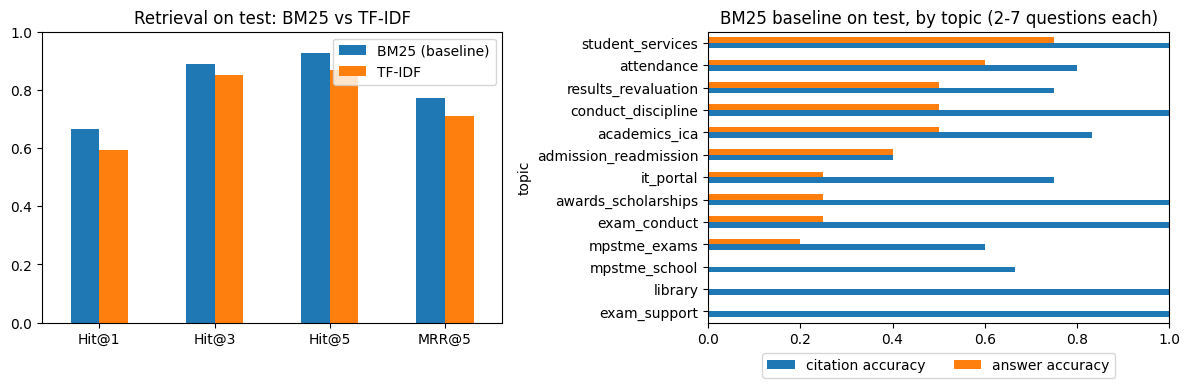

In [16]:
# BM25 vs TF-IDF (same chunks, same threshold) on the test set
res_tfidf = evaluate(KeywordQA(chunks, TfidfRetriever, threshold=THRESHOLD), test, chunks)
rows = ["Hit@1", "Hit@3", "Hit@5", "MRR@5", "Citation accuracy (page)",
        "Answer accuracy (key fact)", "Answer accuracy if never refusing", "Hallucination rate (out-of-scope)"]
comparison = pd.DataFrame({"BM25 (baseline)": summarize(res_test), "TF-IDF": summarize(res_tfidf)}).loc[rows].round(3)
display(comparison)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
comparison.loc[["Hit@1", "Hit@3", "Hit@5", "MRR@5"]].plot.bar(ax=axes[0], rot=0, ylim=(0, 1),
                                                               title="Retrieval on test: BM25 vs TF-IDF")
by_topic = (res_test[res_test.answerable].groupby("topic")[["citation_ok", "answer_ok"]].mean()
            .rename(columns={"citation_ok": "citation accuracy", "answer_ok": "answer accuracy"}).sort_values("answer accuracy"))
by_topic.plot.barh(ax=axes[1], xlim=(0, 1), title="BM25 baseline on test, by topic (2-7 questions each)")
axes[1].legend(loc="upper center", bbox_to_anchor=(0.5, -0.08), ncol=2)
plt.tight_layout(); plt.show()

### 7.3 Error analysis

Every wrong answer on test falls into one of three buckets. This tells us what Week 3 must fix.

In [17]:
errs = res_test[res_test.answerable].copy()
errs["outcome"] = np.select(
    [errs.answer_ok, errs.abstained, errs["rank"] != 1],
    ["correct", "refused (low confidence)", "retrieval miss (wrong passage ranked first)"],
    default="right passage, wrong sentence picked")
display(errs.outcome.value_counts().to_frame("questions"))

for outcome in ["retrieval miss (wrong passage ranked first)", "right passage, wrong sentence picked"]:
    print(f"--- {outcome} ---")
    for r in errs[errs.outcome == outcome].head(2).itertuples():
        print(f"Q: {r.question}\n   gold     : {r.gold_answer}\n   baseline : {r.pred_answer[:160]}\n")

,questions
outcome,
correct,20
retrieval miss (wrong passage ranked first),12
refused (low confidence),12
"right passage, wrong sentence picked",10


--- retrieval miss (wrong passage ranked first) ---
Q: What is the minimum attendance required to appear for the end-semester exam?
   gold     : You need at least 80% attendance in each individual course.
   baseline : 4.2 Non - fulfillment of Passing Criteria: A student, who has failed to fulfil the passing criteria as given above in 4.1, will be required to appear for term /

Q: What do I need to score to pass a course that has only ICA and no final exam?
   gold     : At least 40% of the total ICA marks.
   baseline : 17.8 Announcements: Announcements related to the course, exam timetable and other activities are published in the Announcements section.

--- right passage, wrong sentence picked ---
Q: Am I marked present in regular classes on the day I write a re-exam?
   gold     : Yes. You are marked present for all applicable subjects on the day of your re-examination.
   baseline : 3.1.8 Attendance for Re-examination: Students appearing for a re-examination shall be granted atte

### 7.4 Baseline in action and saved outputs

In [18]:
for q in ["How many days do I get to apply for a photocopy of my answer sheet after results?",   # correct
          "How much is the late fine for a library book?",      # right passage, but the wrong sentence is picked
          "What is the hostel curfew time for students?"]:       # not in the SRB -> refuses
    show(baseline.ask(q), q)

chunks.to_csv(f"{OUT_DIR}/srb_chunks.csv", index=False)
pages[["page", "clean_text"]].to_csv(f"{OUT_DIR}/srb_clean_pages.csv", index=False)
res_test.drop(columns="supporting_text").to_csv(f"{OUT_DIR}/baseline_test_predictions.csv", index=False)
metrics.to_csv(f"{OUT_DIR}/baseline_metrics.csv")
print("Saved:", sorted(os.listdir(OUT_DIR)))

Q: How many days do I get to apply for a photocopy of my answer sheet after results?
  answer         : Result Example: 17th October Application for Verification (retotalling of marks) of Answer-book /Answer Script Within 3 days from the date of result declaration including holidays Example: 20th October Application for Photocopy/ Softcopy of the Answer Script Within 2 days from the date of result declaration including holidays Example: 19th October
  source         : SRB 2026 | Part I (University) | 9. Examination Guidelines | PDF page 21
  confidence     : 0.67
  supporting_text: Result Example: 17th October Application for Verification (retotalling of marks) of Answer-book /Answer Script Within 3 days from the date of result declaration including holidays Example: 20th October Application for Ph...

Q: How much is the late fine for a library book?
  answer         : As the Library is RFID enabled, the issue of the books will be done at self-check-in kiosk only.
  source         : SR

### 7.5 Week-2 checklist (automatic)

In [19]:
demo = baseline.ask("attendance rules")
checks = {
    "Data collection: all SRB pages loaded": len(pages_raw) == doc.page_count,
    "Cleaning: scope filter applied, no empty pages": not pages.page.isin(EXCLUDE).any() and (pages.clean_text.str.len() > 0).all(),
    "Preprocessing: every chunk has page + section": chunks[["page", "section", "text"]].notna().all().all(),
    "Annotation: 60-100 QA pairs, all validated": 60 <= len(qa) <= 100 and not problems,
    "Train/test split: dev and test disjoint, all topics in both": set(dev.qid).isdisjoint(test.qid) and set(dev.topic) == set(test.topic),
    "Baseline: returns answer, source, confidence, supporting_text": {"answer", "source", "confidence", "supporting_text"} <= demo.keys(),
    "Initial evaluation: all metrics computed on test": metrics["test"].notna().all(),
    "Outputs saved for Week 3": all(os.path.exists(f"{OUT_DIR}/{f}") for f in
        ["qa_annotations.csv", "qa_dev.csv", "qa_test.csv", "srb_chunks.csv", "baseline_metrics.csv"]),
}
for name, ok in checks.items():
    print("PASS" if ok else "FAIL", "-", name)
assert all(checks.values())

PASS - Data collection: all SRB pages loaded
PASS - Cleaning: scope filter applied, no empty pages
PASS - Preprocessing: every chunk has page + section
PASS - Annotation: 60-100 QA pairs, all validated
PASS - Train/test split: dev and test disjoint, all topics in both
PASS - Baseline: returns answer, source, confidence, supporting_text
PASS - Initial evaluation: all metrics computed on test
PASS - Outputs saved for Week 3
